# 10 — Model Comparison and Selection

This notebook compares models from Notebooks 05–08 using **only the 2025 validation predictions**. All models are evaluated on the same frozen target observations and dates. The primary selection metric is MAE (MWh/day); RMSE and mean signed error are secondary diagnostics.

The forecasting approach was selected using 2025 validation results. The 2026 holdout must not be used to revise that decision.

In [3]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Works from repository root or code/ in VS Code
ROOT = Path.cwd().parent if Path.cwd().name == "code" else Path.cwd()
assert (ROOT / "data" / "processed" / "features.csv").exists(), "Run from repo root or code/"
TABLES = ROOT / "output" / "tables"
FIGURES = ROOT / "output" / "figures"
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

import importlib.util

validation_path = ROOT / "code" / "09_validation.py"

if not validation_path.exists():
    raise FileNotFoundError(
        f"Cannot find validation module: {validation_path}"
    )

spec = importlib.util.spec_from_file_location(
    "validation",
    validation_path
)

validation = importlib.util.module_from_spec(spec)
spec.loader.exec_module(validation)

print("Successfully loaded:", validation_path.name)


paths = {
    "baseline": "baseline_validation_predictions.csv",
    "linear": "linear_models_validation_predictions.csv",
    "random_forest": "random_forest_validation.csv",
    "random_forest_tuned": "random_forest_tuned_validation.csv",
    "training_windows": "training_windows_validation.csv",
}
inputs = {}
for source, filename in paths.items():
    path = TABLES / filename
    if not path.exists():
        raise FileNotFoundError(path)
    inputs[source] = pd.read_csv(path, parse_dates=["date"])
    print(f"{source}: {len(inputs[source])} rows")

baseline = inputs["baseline"]
linear = inputs["linear"]
rf = inputs["random_forest"]
rf_tuned = inputs["random_forest_tuned"]
windows = inputs["training_windows"]


Successfully loaded: 09_validation.py
baseline: 365 rows
linear: 2190 rows
random_forest: 365 rows
random_forest_tuned: 365 rows
training_windows: 1460 rows


## 2. Verify comparable 2025 predictions **before** ranking models

Checks use the frozen `features.csv` to determine the expected observed 2025 dates, rather than deriving that set from model predictions. We also verify each file's errors and actual values against the frozen target. This prevents misleading comparisons when models silently omit dates.

In [4]:
features = pd.read_csv(ROOT / "data" / "processed" / "features.csv", parse_dates=["date"])
features = features.sort_values("date").reset_index(drop=True)
validation.validate_data(features)

observed_2025 = features.loc[
    (features["date"] >= "2025-01-01") &
    (features["date"] <= "2025-12-31") &
    features["consumption_mwh"].notna(), "date"
]
expected_dates = pd.DatetimeIndex(observed_2025)
assert len(expected_dates) > 0, "No observed 2025 target dates"

for source, pred in inputs.items():
    validation.validate_predictions(pred, expected_year=2025)
    validation.validate_actual_values(pred, features)
    validation.validate_prediction_coverage(pred, expected_dates=expected_dates)

# All source tables pass the checks before results are calculated.
all_predictions = pd.concat(
    [frame.assign(source=source) for source, frame in inputs.items()],
    ignore_index=True
)

results = []
for (source, model), group in all_predictions.groupby(["source", "model"]):
    m = validation.compute_metrics(group["actual_mwh"], group["predicted_mwh"])
    results.append({"source": source, "model": model,
                    "n_days": m["n_days"], "MAE": m["mae_mwh"],
                    "RMSE": m["rmse_mwh"], "mean_error_mwh": m["mean_error_mwh"]})
comparison = pd.DataFrame(results).sort_values("MAE").reset_index(drop=True)
display(comparison.round(2))


Data validation passed.
Total observations: 3226
Rows with missing targets: 0
Missing calendar dates within train: 0
Missing calendar dates within validation: 0
Missing calendar dates within test: 0
Prediction validation passed.
Models: 1
Predictions: 365
Actual consumption values match features.csv.
Prediction coverage validation passed.
Models checked: 1
Expected dates: 365
Prediction validation passed.
Models: 6
Predictions: 2190
Actual consumption values match features.csv.
Prediction coverage validation passed.
Models checked: 6
Expected dates: 365
Prediction validation passed.
Models: 1
Predictions: 365
Actual consumption values match features.csv.
Prediction coverage validation passed.
Models checked: 1
Expected dates: 365
Prediction validation passed.
Models: 1
Predictions: 365
Actual consumption values match features.csv.
Prediction coverage validation passed.
Models checked: 1
Expected dates: 365
Prediction validation passed.
Models: 4
Predictions: 1460
Actual consumption val

,source,model,n_days,MAE,RMSE,mean_error_mwh
0,training_windows,ols_rolling_3y,365,74.64,97.66,-25.59
1,training_windows,ols_expanding,365,80.36,105.44,-23.15
2,linear,ols_with_weather,365,80.36,105.44,-23.15
3,training_windows,random_forest_rolling_3y,365,81.66,104.18,-11.89
4,linear,ridge_with_weather,365,81.79,107.45,-23.81
5,linear,lasso_with_weather,365,83.57,109.15,-25.05
6,random_forest,random_forest_expanding,365,86.79,115.27,-21.64
7,training_windows,random_forest_expanding,365,86.79,115.27,-21.64
8,random_forest_tuned,random_forest_tuned_expanding,365,87.24,115.99,-21.73
9,linear,ols_no_weather,365,99.55,130.96,-19.87


## 3. Initial ranking (includes repeated implementations)

This preliminary figure includes copies of the expanding OLS and Random Forest results from Notebook 08. We verify and remove these copies before producing the final ranking.

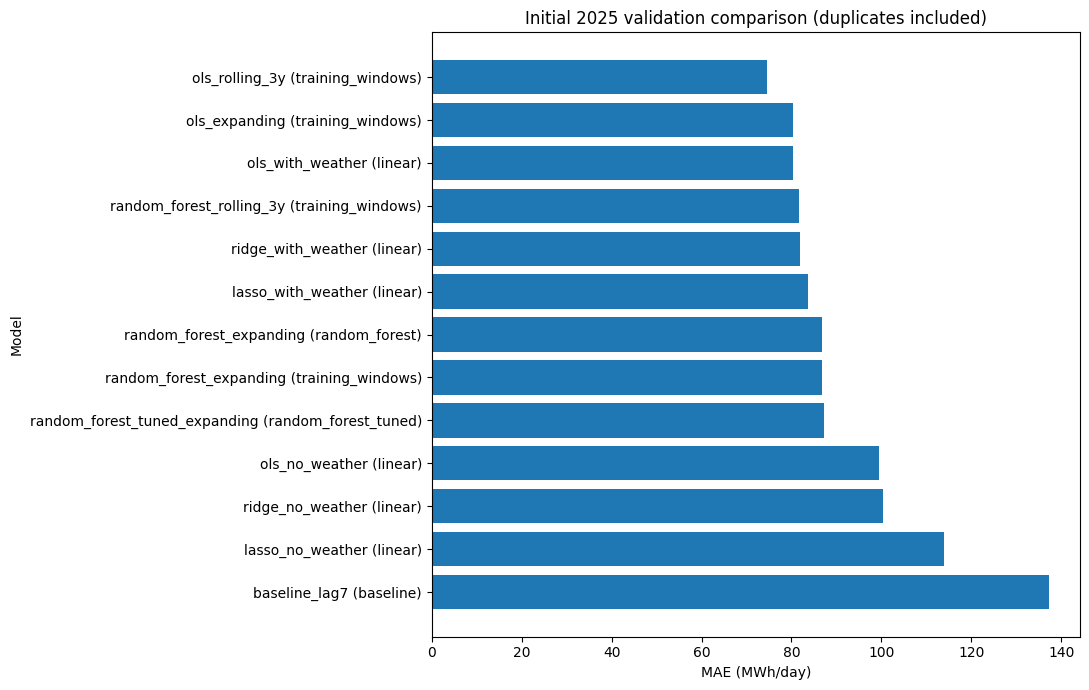

In [5]:
plot_data = comparison.copy()
plot_data["label"] = plot_data["model"] + " (" + plot_data["source"] + ")"
fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(plot_data["label"], plot_data["MAE"])
ax.set(xlabel="MAE (MWh/day)", ylabel="Model", title="Initial 2025 validation comparison (duplicates included)")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## 4. Check equivalent expanding-window implementations

Notebook 08 reproduced Person 2's expanding OLS and Person 3's expanding Random Forest. These are **not** independent additional models. Equality is checked by date and actual/predicted values before removing duplicate variants.

In [6]:
def compare_predictions(first, second):
    cols = ["date", "actual_mwh", "predicted_mwh"]
    a = first[cols].copy()
    b = second[cols].copy()
    assert a["date"].is_unique and b["date"].is_unique
    merged = a.merge(b, on="date", suffixes=("_a", "_b"), validate="one_to_one")
    if len(merged) != len(a) or len(merged) != len(b):
        return False
    return (
        np.allclose(merged["actual_mwh_a"], merged["actual_mwh_b"], rtol=0, atol=1e-6)
        and np.allclose(merged["predicted_mwh_a"], merged["predicted_mwh_b"], rtol=0, atol=1e-6)
    )

ols_same = compare_predictions(
    linear.loc[linear["model"] == "ols_with_weather"],
    windows.loc[windows["model"] == "ols_expanding"]
)
rf_same = compare_predictions(
    rf.loc[rf["model"] == "random_forest_expanding"],
    windows.loc[windows["model"] == "random_forest_expanding"]
)
print("Expanding OLS predictions identical:", ols_same)
print("Expanding RF predictions identical:", rf_same)
assert ols_same and rf_same, "Reproduced models differ: resolve before removing copies"


Expanding OLS predictions identical: True
Expanding RF predictions identical: True


## 5. Remove verified duplicate variants

Retain the original OLS and Random Forest expanding predictions, and omit their replicated Notebook 08 counterparts. The rolling-window variants remain distinct.

In [7]:
duplicate_mask = (
    (comparison["source"] == "training_windows")
    & comparison["model"].isin(["ols_expanding", "random_forest_expanding"])
)
clean_comparison = comparison.loc[~duplicate_mask].sort_values("MAE").reset_index(drop=True)
clean_predictions = all_predictions.loc[
    ~((all_predictions["source"] == "training_windows")
      & all_predictions["model"].isin(["ols_expanding", "random_forest_expanding"]))
].copy()
assert clean_comparison["model"].is_unique, "Model labels must be unique after deduplication"
print("Unique model configurations:", len(clean_comparison))
display(clean_comparison.round(2))


Unique model configurations: 11


,source,model,n_days,MAE,RMSE,mean_error_mwh
0,training_windows,ols_rolling_3y,365,74.64,97.66,-25.59
1,linear,ols_with_weather,365,80.36,105.44,-23.15
2,training_windows,random_forest_rolling_3y,365,81.66,104.18,-11.89
3,linear,ridge_with_weather,365,81.79,107.45,-23.81
4,linear,lasso_with_weather,365,83.57,109.15,-25.05
5,random_forest,random_forest_expanding,365,86.79,115.27,-21.64
6,random_forest_tuned,random_forest_tuned_expanding,365,87.24,115.99,-21.73
7,linear,ols_no_weather,365,99.55,130.96,-19.87
8,linear,ridge_no_weather,365,100.27,131.54,-19.06
9,linear,lasso_no_weather,365,113.99,148.90,-17.13


## 6. Improvement relative to the lag-7 baseline

Positive values indicate smaller errors than the baseline. Mean signed error is **actual minus predicted**, so a negative mean error indicates average overprediction.

In [8]:
baseline_row = clean_comparison.loc[clean_comparison["model"] == "baseline_lag7"]
assert len(baseline_row) == 1
baseline_mae = baseline_row["MAE"].iloc[0]
baseline_rmse = baseline_row["RMSE"].iloc[0]
clean_comparison["MAE_improvement_%"] = 100 * (1 - clean_comparison["MAE"] / baseline_mae)
clean_comparison["RMSE_improvement_%"] = 100 * (1 - clean_comparison["RMSE"] / baseline_rmse)
display(clean_comparison.round(2))


,source,model,n_days,MAE,RMSE,mean_error_mwh,MAE_improvement_%,RMSE_improvement_%
0,training_windows,ols_rolling_3y,365,74.64,97.66,-25.59,45.62,51.54
1,linear,ols_with_weather,365,80.36,105.44,-23.15,41.46,47.68
2,training_windows,random_forest_rolling_3y,365,81.66,104.18,-11.89,40.52,48.31
3,linear,ridge_with_weather,365,81.79,107.45,-23.81,40.42,46.69
4,linear,lasso_with_weather,365,83.57,109.15,-25.05,39.12,45.84
5,random_forest,random_forest_expanding,365,86.79,115.27,-21.64,36.78,42.81
6,random_forest_tuned,random_forest_tuned_expanding,365,87.24,115.99,-21.73,36.45,42.45
7,linear,ols_no_weather,365,99.55,130.96,-19.87,27.48,35.02
8,linear,ridge_no_weather,365,100.27,131.54,-19.06,26.96,34.73
9,linear,lasso_no_weather,365,113.99,148.90,-17.13,16.96,26.12


## 7. Final model ranking

The final table includes MAE, RMSE, mean signed error and the number of matched validation dates. Model selection is based primarily on the **lowest 2025 MAE**.

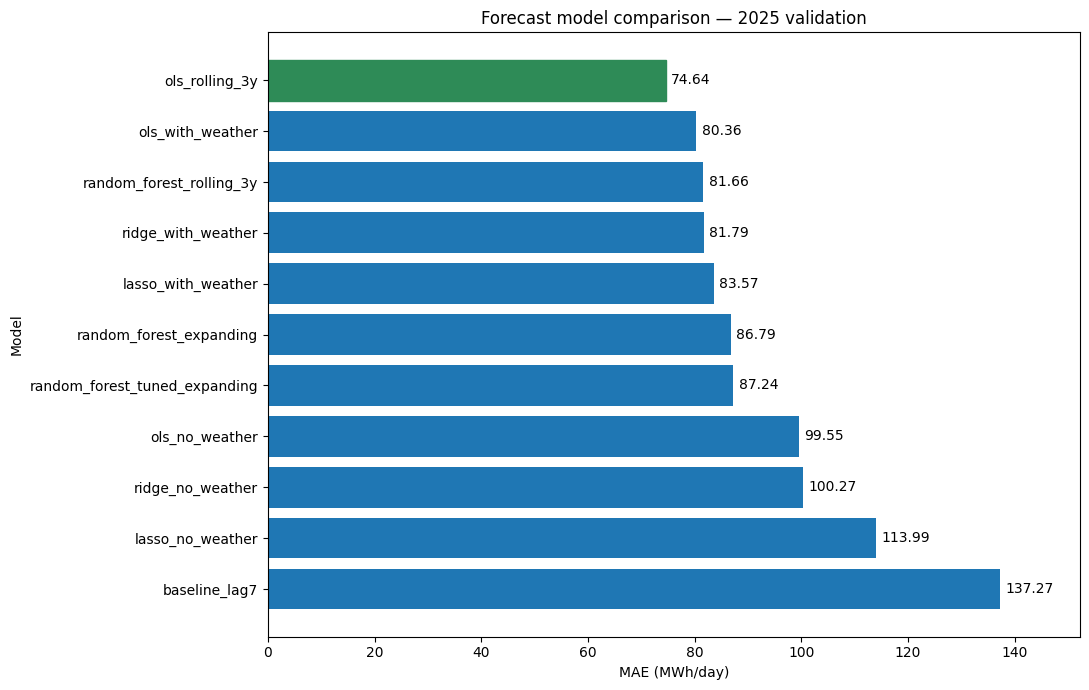

In [9]:
plot_data = clean_comparison.copy()
fig, ax = plt.subplots(figsize=(11, 7))
bars = ax.barh(plot_data["model"], plot_data["MAE"])
bars[0].set_color("seagreen")
for bar, mae in zip(bars, plot_data["MAE"]):
    ax.text(mae + 1, bar.get_y() + bar.get_height()/2, f"{mae:.2f}", va="center")
ax.set(xlabel="MAE (MWh/day)", ylabel="Model", title="Forecast model comparison — 2025 validation")
ax.invert_yaxis()
ax.set_xlim(0, plot_data["MAE"].max() + 15)
plt.tight_layout()
fig.savefig(FIGURES / "final_validation_model_mae.png", dpi=300, bbox_inches="tight")
plt.show()


## 8. Monthly forecast errors

Compare monthly MAE for the lag-7 baseline, expanding OLS with weather, and rolling three-year OLS. These are all calculated from the same observed 2025 dates; overall MAE remains a daily weighted average, not an unweighted average of monthly MAEs.

In [10]:
selected_names = ["baseline_lag7", "ols_with_weather", "ols_rolling_3y"]
selected_predictions = clean_predictions.loc[clean_predictions["model"].isin(selected_names)].copy()
assert selected_predictions["model"].nunique() == 3
selected_predictions["month"] = selected_predictions["date"].dt.strftime("%Y-%m")
selected_predictions["absolute_error"] = (selected_predictions["actual_mwh"] - selected_predictions["predicted_mwh"]).abs()
monthly_mae = selected_predictions.groupby(["month", "model"])["absolute_error"].mean().unstack()
assert len(monthly_mae) == 12
assert monthly_mae.notna().all().all()
display(monthly_mae.round(2))
monthly_mae.to_csv(TABLES / "final_validation_monthly.csv", index_label="month")


model,baseline_lag7,ols_rolling_3y,ols_with_weather
month,,,
2025-01,163.27,91.22,119.63
2025-02,88.99,76.49,45.90
2025-03,126.53,67.48,88.96
2025-04,116.45,62.16,66.27
2025-05,147.09,75.46,83.25
2025-06,193.09,76.39,85.33
2025-07,195.13,105.42,138.37
2025-08,240.51,116.81,87.68
2025-09,92.39,46.19,58.10


## 9. Monthly error visualization

The chart compares performance across the 12 validation months. All plotted MAEs are in MWh/day.

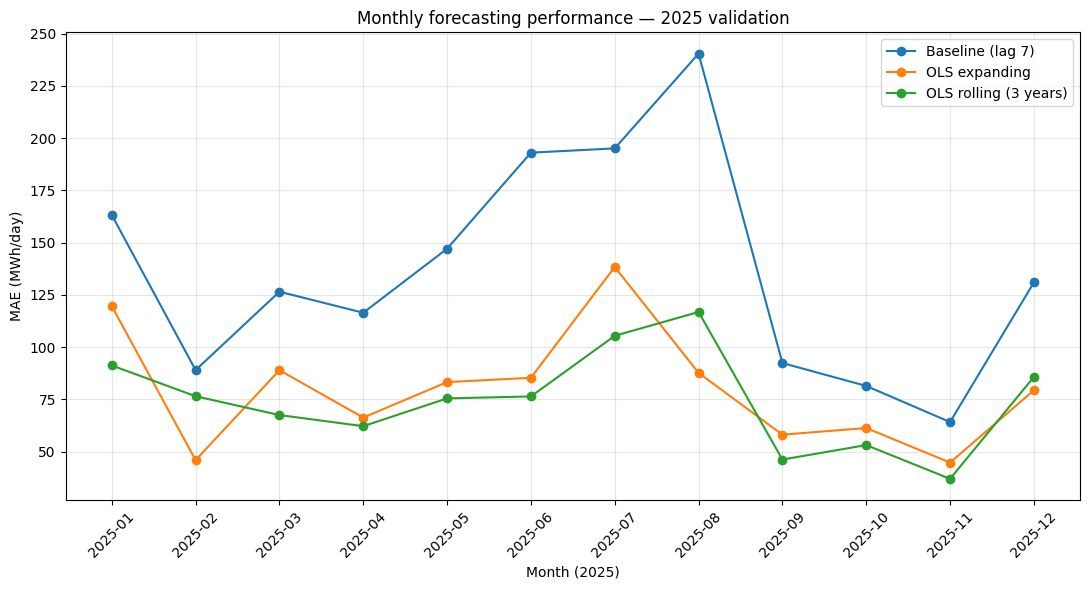

In [11]:
fig, ax = plt.subplots(figsize=(11, 6))
for name, label in [
    ("baseline_lag7", "Baseline (lag 7)"),
    ("ols_with_weather", "OLS expanding"),
    ("ols_rolling_3y", "OLS rolling (3 years)"),
]:
    ax.plot(monthly_mae.index, monthly_mae[name], marker="o", label=label)
ax.set(xlabel="Month (2025)", ylabel="MAE (MWh/day)", title="Monthly forecasting performance — 2025 validation")
ax.tick_params(axis="x", rotation=45)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(FIGURES / "final_validation_monthly_mae.png", dpi=300, bbox_inches="tight")
plt.show()


## 10. Model selection and handover to the final test

The final model is selected **exclusively from the 2025 validation predictions**, based primarily on the lowest MAE. The selected approach will be evaluated as already specified on the January–October 2026 holdout; viewing test results must not change this selection.

The selected model must use exactly the OLS-with-weather preprocessing and features from Notebook 08, a rolling three-year window, and monthly refitting with the target-date five-day cutoff. We export the selected model ID and evaluation policy for reproducibility.

In [12]:
# Verify the 2025-selected model, then persist the frozen selection.
selected_row = clean_comparison.iloc[0]
selected_id = str(selected_row["model"])
print("Selected on 2025 validation:", selected_id)
print("MAE:", round(float(selected_row["MAE"]), 4), "MWh/day")
assert selected_id == "ols_rolling_3y", (
    "Selection differs from the previously documented 2025 decision. "
    "Investigate source files before making any change; do not use 2026 results."
)
clean_comparison.to_csv(TABLES / "final_validation_comparison.csv", index=False)
selection = {
    "selected_model": selected_id,
    "selection_period": "2025-01-01 to 2025-12-31",
    "selection_metric": "MAE (MWh/day)",
    "training_window": "rolling_3y",
    "train_target_cutoff_days_before_first_target": 5,
    "refit_frequency": "monthly",
    "specification_reference": "code/08_training_windows.ipynb — make_ols_pipeline and FEATURES",
    "note": "Selection based on 2025 validation only; do not revise using 2026 test results."
}
with (TABLES / "selected_model_config.json").open("w", encoding="utf-8") as f:
    json.dump(selection, f, indent=2)
print("Saved final_validation_comparison.csv, final_validation_monthly.csv, selected_model_config.json")

Selected on 2025 validation: ols_rolling_3y
MAE: 74.6436 MWh/day
Saved final_validation_comparison.csv, final_validation_monthly.csv, selected_model_config.json
